# Baseline 2 — ConvNeXt-Tiny V1 (CN01)
**Out-of-Distribution Plant Disease Identification | Development-only Stage 1**

**Research question:** Does replacing the shared pretrained ResNet-50 backbone with pretrained ConvNeXt-Tiny improve crop recognition, disease recognition, and unseen crop–disease composition accuracy while keeping the same two-head multi-task method?

This notebook is a **new experiment**, not an edit of the executed ResNet-50 notebooks. It uses the fixed 6,905 / 695 / 400 development split and 9,625 candidate pairs. **It never reads Official Test CSVs or images.** No training runs until `RUN_TRAINING=True` is explicitly set in Section 5.

The model uses shared ConvNeXt-Tiny features and independent **55-class crop** and **175-class disease** classifiers. Composition predictions come from the sum of crop and disease log-probabilities. We use standard CE only (no SupCon, prototypes, cRT or calibration).

## 1. Imports, project paths, and GPU information

Open this notebook inside your existing `C:\AML\ML_Project\Baseline2\notebooks\convnext\` folder. It searches upward for `evaluate.py` and `splits_v2/`. Photos should be directly inside `C:\AML\ML_Project\DPD_Small_dataset` as in the previous ResNet experiments. The existing `evaluate.py` is imported **without editing it**.

In [1]:
from pathlib import Path
import os
import sys

start = Path(os.environ.get("B2_PROJECT_ROOT", Path.cwd())).expanduser().resolve()
PROJECT_DIR = next((p for p in [start, *start.parents] if (p / "evaluate.py").is_file()
                    and (p / "splits_v2").is_dir() and (p / "model_convnext.py").is_file()), None)
if PROJECT_DIR is None:
    fallback_roots = [start / "Baseline2", Path(r"C:\AML\ML_Project\Baseline2")]
    PROJECT_DIR = next((p for p in fallback_roots if (p / "evaluate.py").is_file()
                        and (p / "splits_v2").is_dir() and (p / "model_convnext.py").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Open inside the Baseline2 project or set B2_PROJECT_ROOT to the Baseline2 folder.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import json
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from IPython.display import display, Image as IPyImage

from model_convnext import MultiTaskConvNeXtTiny, load_convnext_checkpoint
from convnext_cn01_utils import (
    default_config, validate_config, find_training_images, split_preflight,
    smoke_test_model, cuda_memory_preflight, fit_stage1, audit_development,
)

IMAGE_ROOT = find_training_images(PROJECT_DIR)
SPLIT_DIR = PROJECT_DIR / "splits_v2"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "convnext_cn01"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project:", PROJECT_DIR)
print("Training image directory:", IMAGE_ROOT)
print("Split directory:", SPLIT_DIR)
print("Output directory:", OUTPUT_DIR)
print("PyTorch:", torch.__version__, "| Torchvision:", torchvision.__version__)
print("Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "not available")

Project: C:\AML\ML_Project\Baseline2
Training image directory: C:\AML\ML_Project\DPD_Small_dataset
Split directory: C:\AML\ML_Project\Baseline2\splits_v2
Output directory: C:\AML\ML_Project\Baseline2\outputs\convnext_cn01
PyTorch: 2.11.0+cu128 | Torchvision: 0.26.0+cu128
Device: cuda | GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 2. CN01 configuration and controlled comparison

ResNet-50 Exp09 is the reference. Match 224×224 input, augmentation, bilinear validation resizing, dropout, CE task weights, AdamW, separate learning rates, weight decay, cosine schedule, seed, candidate scoring, and checkpoint selection criterion. The intended treatment is **the shared backbone**. Practical differences: ConvNeXt-Tiny replaces ResNet-50; default physical batch is **8 with two gradient accumulation steps** (approx. effective batch 16), and `num_workers=0` is chosen for safe Windows notebook execution (Exp09 used batch 16 / 4 workers). These differences must be reported as experimental limitations.

If the GPU memory preflight fails at batch 8, reduce to batch 4 with accumulation 4 **before the first run**; preserve effective batch 16. Avoid changing anything halfway through an experiment.

In [2]:
CONFIG = default_config()  # Exp09-aligned CN01; disease weight 1.0, seed 42

# Change only the two following settings BEFORE first training if GPU preflight OOMs:
# CONFIG["batch_size"] = 4
# CONFIG["gradient_accumulation_steps"] = 4
# CONFIG["effective_batch_size"] = 16

assert validate_config(CONFIG)
display(pd.DataFrame([{"parameter": k, "value": str(v)} for k, v in CONFIG.items()]))

,parameter,value
0,experiment_id,convnext_cn01
1,backbone,convnext_tiny
2,pretrained_weights,IMAGENET1K_V1
3,crop_classes,55
4,disease_classes,175
5,image_size,224
6,batch_size,8
7,gradient_accumulation_steps,2
8,effective_batch_size,16
9,max_epochs,30


## 3. Verify fixed development splits (NO official test)

Uses the existing `splits_v2` directory. Checks disjoint filenames, 10 completely held-out combinations, coverage of individual crop and disease IDs, and **exact SHA256 hashes recorded by the executed Exp09 notebook**. It also checks that every listed training image path exists under `IMAGE_ROOT`. It only uses CSV-listed training images, never scans for test files.

In [3]:
frames, split_report, candidates = split_preflight(PROJECT_DIR, IMAGE_ROOT, verify_decode=False)
display(pd.DataFrame({"split": ["Train fit", "Seen validation", "Unseen validation"],
                      "images": [len(frames[k]) for k in ("train_fit", "val_seen", "val_unseen")],
                      "crops": [frames[k].crop_id.nunique() for k in ("train_fit", "val_seen", "val_unseen")],
                      "diseases": [frames[k].disease_id.nunique() for k in ("train_fit", "val_seen", "val_unseen")],
                      "compositions": [frames[k].composition_id.nunique() for k in ("train_fit", "val_seen", "val_unseen")] }))
print("Development hashes equal the executed Exp09 record:", True)
print("Global candidate pairs:", len(candidates))
print("Candidate first / last:", candidates[0].tolist(), candidates[-1].tolist())

,split,images,crops,diseases,compositions
0,Train fit,6905,55,175,313
1,Seen validation,695,55,155,273
2,Unseen validation,400,10,8,10


Development hashes equal the executed Exp09 record: True
Global candidate pairs: 9625
Candidate first / last: [0, 0] [54, 174]


## 4. Synthetic model checks and CUDA preflight (no training data)

First checks the model in CPU memory: output shapes `(2,55)/(2,175)`, shared gradients, optimiser parameter uniqueness, composition scoring, and checkpoint save/load, all using **random synthetic tensors** without downloading weights. If CUDA is available, try a training-sized synthetic minibatch with AMP and AdamW to detect out-of-memory before launching a long run.

Finally, optionally decode all 8,000 CSV-listed development images to confirm that the real training files are readable. This is not training.

In [4]:
print(smoke_test_model())
GPU_CHECK = cuda_memory_preflight(CONFIG)
print("CUDA synthetic minibatch preflight:", GPU_CHECK)

RUN_FULL_IMAGE_DECODE = True
if RUN_FULL_IMAGE_DECODE:
    frames, split_report, candidates = split_preflight(PROJECT_DIR, IMAGE_ROOT, verify_decode=True)
    print("All 8,000 training-development images decoded successfully.")
PREFLIGHT_PASSED = True
print("Preflight PASSED. Review configuration before enabling training.")

Synthetic metric + Exp06 calibration checks passed; no dataset accessed.
Synthetic CPU PASS: heads, shared gradients, parameters, pairs, checkpoint save/load
CUDA synthetic minibatch preflight: {'cuda_available': True, 'batch_tested': 8, 'amp': True, 'peak_allocated_GiB': 0.67, 'passed': True}
All 8,000 training-development images decoded successfully.
Preflight PASSED. Review configuration before enabling training.


## 5. Stage 1 training — manual opt-in

**First run:** set `RUN_TRAINING = True` below. This will train **CN01 only**, with ImageNet weights downloaded (or loaded from Torch's cache). It will create `outputs/convnext_cn01/` only if that directory does not already exist, and save history/checkpoints after every epoch. Never run the same completed experiment a second time.

If training was interrupted between epochs, **keep every configuration value unchanged**, set `RESUME_INTERRUPTED = True`, and rerun this section to load `last_training.pt`. If CUDA isn't available, this section will stop rather than silently train for a long time on CPU. All checkpoint selection uses **development composition HM**, not Official Test performance.

In [5]:
RUN_TRAINING = True  # <-- SET True only after preflight and reviewing CONFIG.
RESUME_INTERRUPTED = False  # <-- Only True when continuing an interrupted SAME CN01 run.

if RUN_TRAINING:
    assert PREFLIGHT_PASSED, "Complete Section 4 preflight first."
    if not GPU_CHECK.get("passed", False):
        raise RuntimeError("CUDA memory preflight did not pass; do not start full training.")
    finished_dir = fit_stage1(PROJECT_DIR, IMAGE_ROOT, CONFIG,
                              frames, split_report, candidates,
                              resume=RESUME_INTERRUPTED)
    print("Stage 1 outputs:", finished_dir)
else:
    print("Stage 1 disabled safely. Set RUN_TRAINING=True above when you want to start.")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to C:\Users\User/.cache\torch\hub\checkpoints\convnext_tiny-983f1562.pth


100.0%


Epoch 01 | train loss=2.8445 | seen=57.55% | unseen=0.50% | HM=0.99%  [BEST]
Epoch 02 | train loss=1.0875 | seen=66.91% | unseen=2.50% | HM=4.82%  [BEST]
Epoch 03 | train loss=0.6804 | seen=69.78% | unseen=4.00% | HM=7.57%  [BEST]
Epoch 04 | train loss=0.4938 | seen=70.50% | unseen=4.00% | HM=7.57%  [BEST]
Epoch 05 | train loss=0.3795 | seen=71.51% | unseen=2.75% | HM=5.30%
Epoch 06 | train loss=0.3008 | seen=73.53% | unseen=3.25% | HM=6.22%
Epoch 07 | train loss=0.2436 | seen=73.96% | unseen=3.75% | HM=7.14%
Epoch 08 | train loss=0.1996 | seen=72.52% | unseen=2.75% | HM=5.30%
Epoch 09 | train loss=0.1672 | seen=74.10% | unseen=3.00% | HM=5.77%
Epoch 10 | train loss=0.1476 | seen=72.09% | unseen=2.50% | HM=4.83%
Epoch 11 | train loss=0.1201 | seen=73.96% | unseen=3.25% | HM=6.23%
Epoch 12 | train loss=0.1075 | seen=75.40% | unseen=3.00% | HM=5.77%
Epoch 13 | train loss=0.1021 | seen=74.96% | unseen=3.25% | HM=6.23%
Epoch 14 | train loss=0.0899 | seen=75.25% | unseen=3.25% | HM=6.23%
Ep

## 6. Development-only evaluation and error analysis

When `best_development.pt` exists, this section evaluates **only the selected development checkpoint** on both validation partitions. It saves crop/disease/composition Top-1 and Top-5, seen–unseen HM, macro class accuracies, per-class support, seen-pair prediction bias, full confusion CSVs, compact confusion figures, classification-error groups, and real incorrectly classified **development** image examples.

The result table compares CN01 to the **historical Exp09 and Exp15 development records**. This is *not* a comparison against the previously completed Official Test results.

In [6]:
RUN_DEVELOPMENT_AUDIT = True
if RUN_DEVELOPMENT_AUDIT and (OUTPUT_DIR / "best_development.pt").is_file():
    audit, comparison = audit_development(PROJECT_DIR, IMAGE_ROOT, CONFIG)
    summary = pd.DataFrame([
        {"split": split, "crop_top1": audit[split]["crop_top1"],
         "disease_top1": audit[split]["disease_top1"],
         "composition_top1": audit[split]["composition_top1"],
         "composition_top5": audit[split]["composition_top5"]}
        for split in ("seen", "unseen")
    ]).set_index("split")
    display((summary * 100).round(2).rename(columns=lambda x: x + " (%)"))
    print("Composition HM:", f"{audit['composition_harmonic_mean']:.2%}")
    print("Selected best epoch:", audit["checkpoint_epoch"])
    for split in ("seen", "unseen"):
        print(split, "error categories:", audit[split]["error_breakdown"])
        print(split, "predicted train-seen pair fraction:", f"{audit[split]['fraction_predictions_in_training_compositions']:.2%}")
    display(comparison.assign(
        seen_composition_top1=lambda d: (100*d.seen_composition_top1).round(2),
        unseen_composition_top1=lambda d: (100*d.unseen_composition_top1).round(2),
        composition_hm=lambda d: (100*d.composition_hm).round(2)
    ).rename(columns={"seen_composition_top1": "seen_top1_pct",
                      "unseen_composition_top1": "unseen_top1_pct", "composition_hm": "hm_pct"}))
    print("Full development audit saved to:", OUTPUT_DIR)
else:
    print("No CN01 checkpoint found or audit disabled; there are no genuine CN01 results to display yet.")

,crop_top1 (%),disease_top1 (%),composition_top1 (%),composition_top5 (%)
split,,,,
seen,89.93,78.85,75.83,87.63
unseen,69.75,21.75,4.00,15.25


Composition HM: 7.60%
Selected best epoch: 15
seen error categories: {'crop_only_correct': 98, 'disease_only_correct': 21, 'both_correct': 527, 'neither_correct': 49}
seen predicted train-seen pair fraction: 93.24%
unseen error categories: {'crop_only_correct': 263, 'disease_only_correct': 71, 'both_correct': 16, 'neither_correct': 50}
unseen predicted train-seen pair fraction: 84.75%


,run,source,backbone,physical_batch,accumulation_steps,disease_weight,seen_top1_pct,unseen_top1_pct,hm_pct
0,ResNet-50 Exp09,historical executed notebook,ResNet-50 ImageNet V2,16,1,1.0,72.95,4.00,7.58
1,ResNet-50 Exp15,historical executed notebook,ResNet-50 ImageNet V2,16,1,1.5,72.52,4.25,8.03
2,ConvNeXt CN01,new development evaluation,ConvNeXt-Tiny ImageNet V1,8,2,1.0,75.83,4.00,7.60


Full development audit saved to: C:\AML\ML_Project\Baseline2\outputs\convnext_cn01


## 7. Saved figures (actual execution outputs only)

These figures appear after running Stage 1 and the development audit. No fabricated images or metrics are embedded in the notebook. For GitHub evidence, save this notebook with executed cells and preserve the `outputs/convnext_cn01` figures/CSV; avoid committing large weights unless your team agrees on storage strategy.

training_curves.png


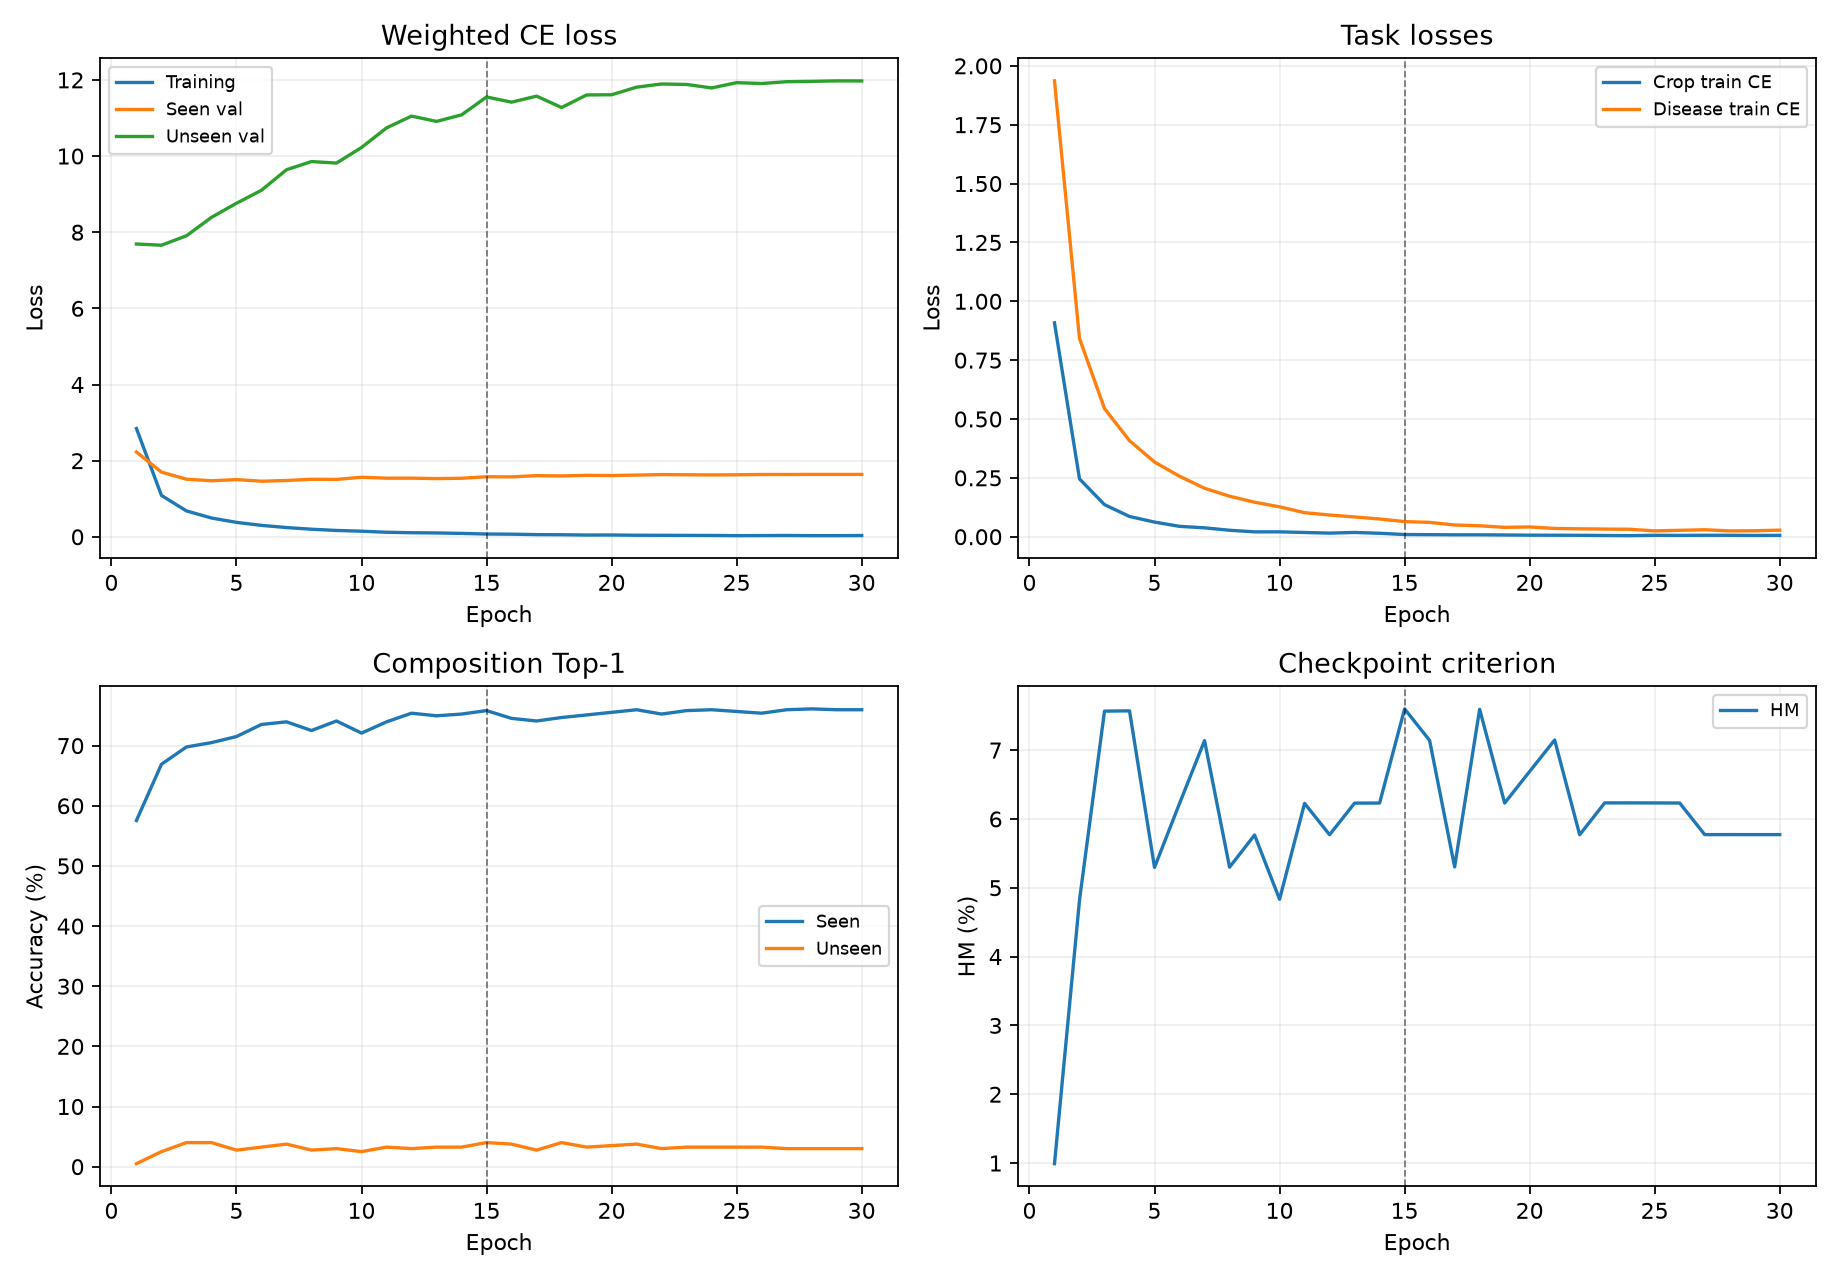

val_seen_crop_confusion_top20.png


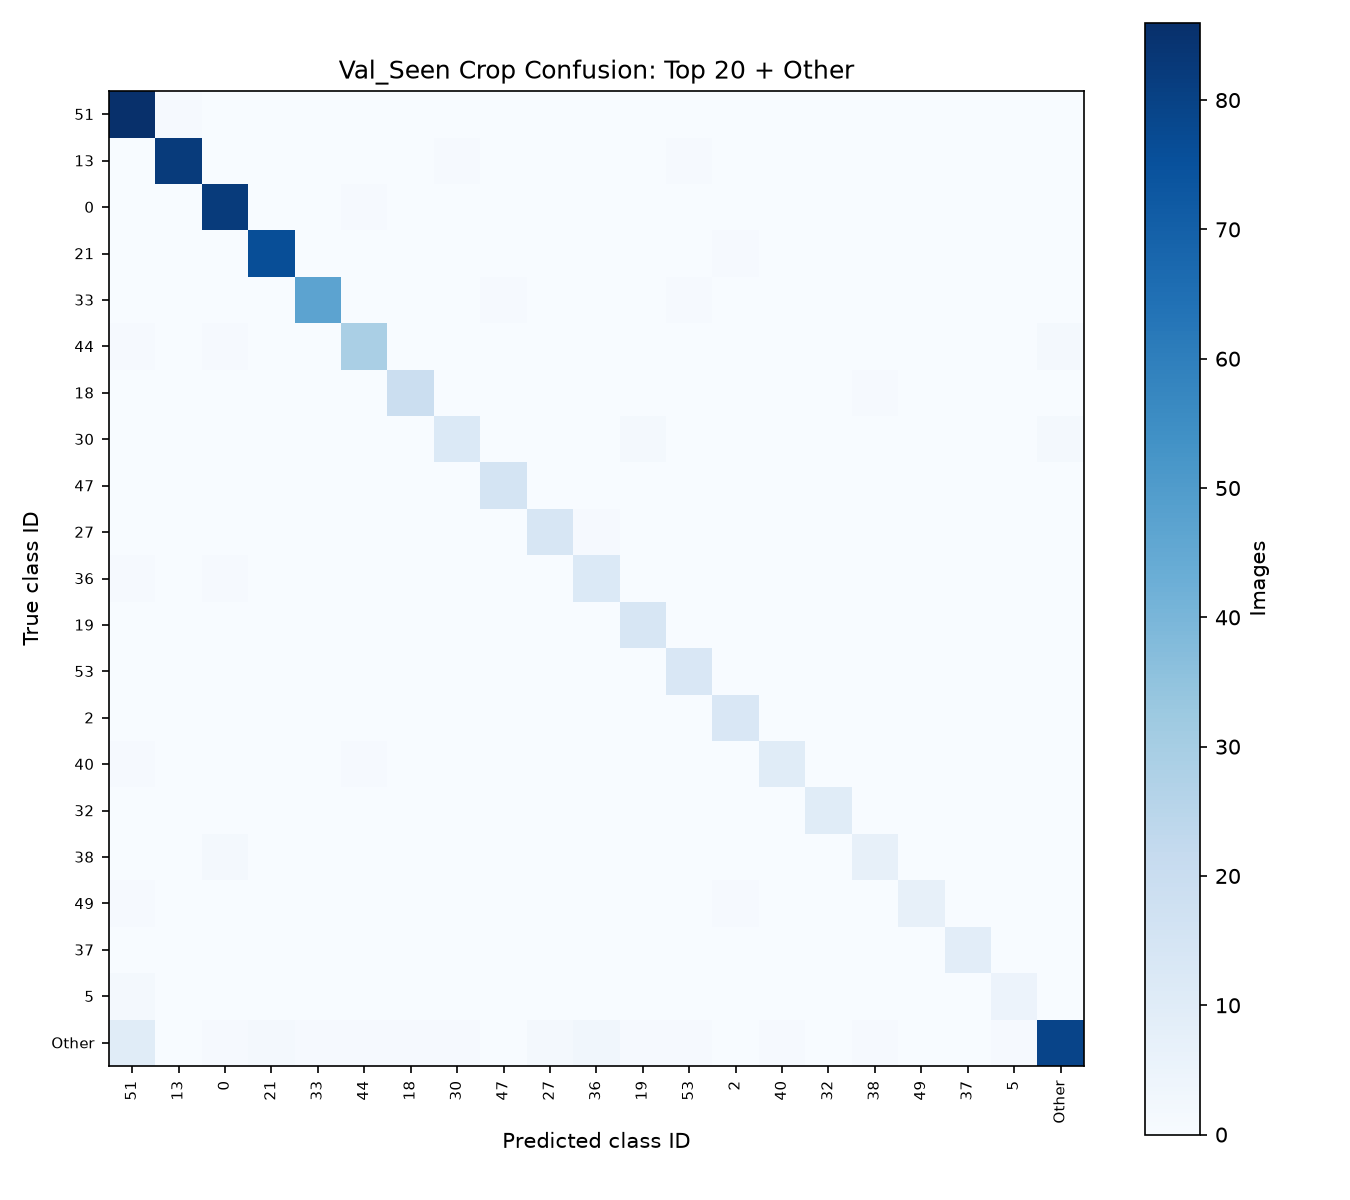

val_seen_disease_confusion_top20.png


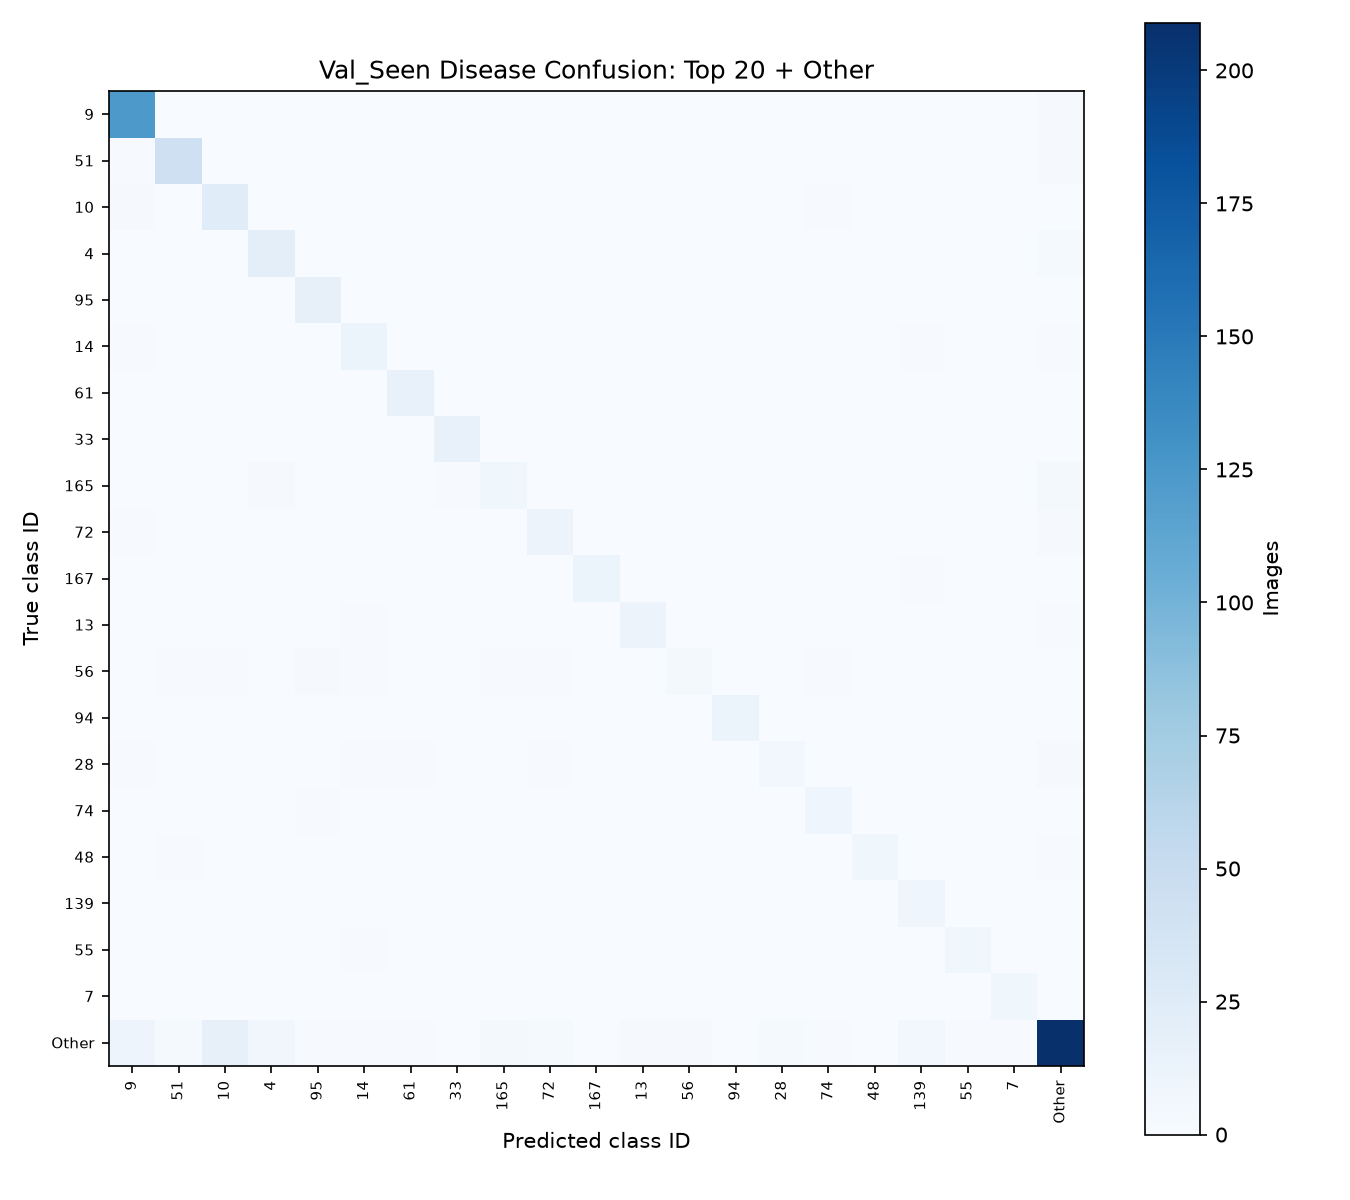

val_unseen_disease_confusion_top20.png


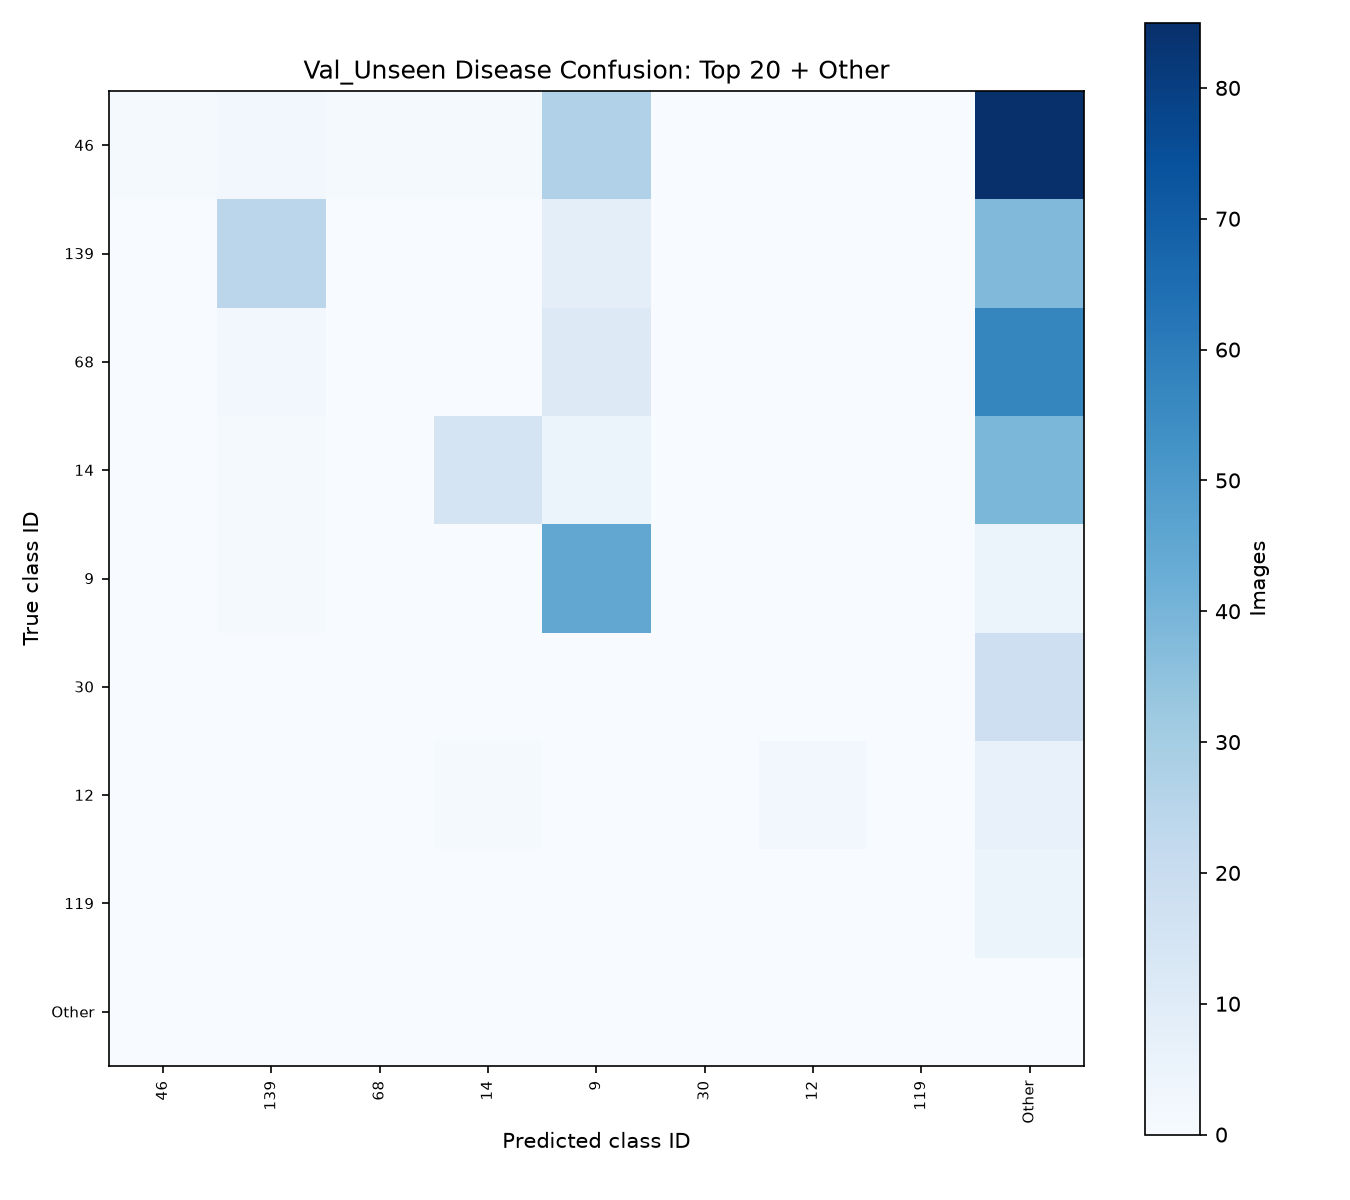

val_unseen_error_examples.png


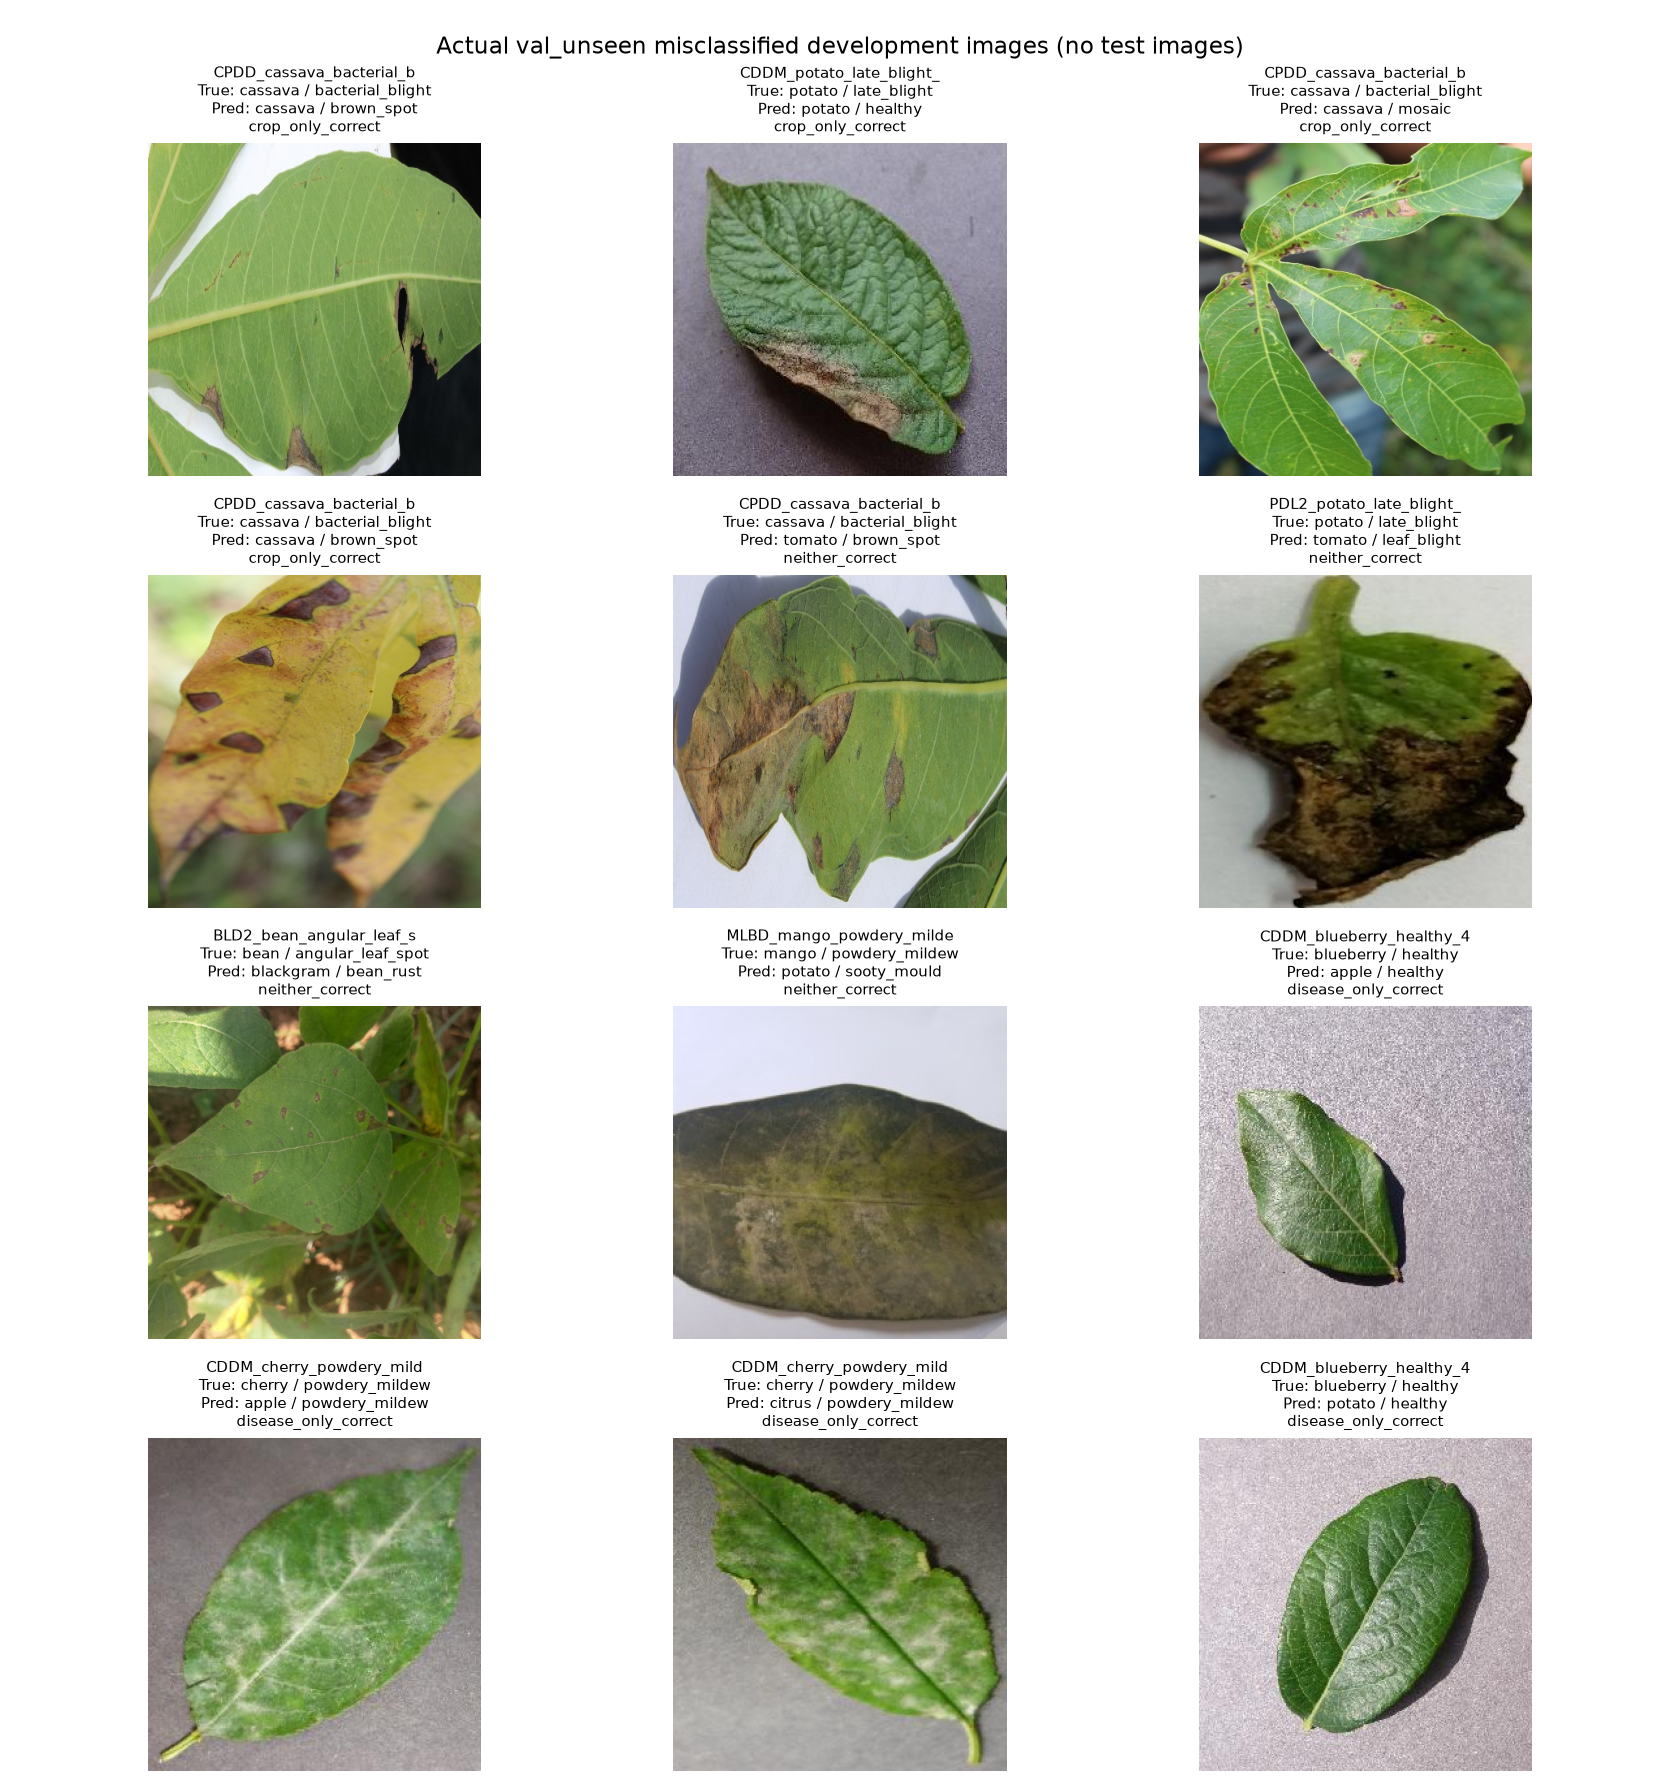

In [7]:
figures = ["training_curves.png", "val_seen_crop_confusion_top20.png",
           "val_seen_disease_confusion_top20.png", "val_unseen_disease_confusion_top20.png",
           "val_unseen_error_examples.png"]
for filename in figures:
    path = OUTPUT_DIR / filename
    if path.is_file():
        print(filename)
        display(IPyImage(filename=str(path)))
    else:
        print("Not generated yet:", filename)

## 8. Interpretation, fairness, and limitations

1. **Hypothesis, not conclusion:** ConvNeXt's learned visual representations may transfer differently to crop and disease classification; this does not guarantee unseen-composition improvement.
2. Compare **Exp09 vs CN01** as the primary shared-MTL experiment. Exp15 differs in disease loss weight and is secondary context. A stronger result in one seed is **descriptive**, not statistical proof.
3. Exp09 uses **ResNet-50 ImageNet V2** weights; CN01 uses **ConvNeXt-Tiny ImageNet V1**. The architectures, ImageNet pretraining recipes, microbatch size, and worker settings are not identical. Interpret performance as a *practical pretrained backbone substitution*, not a perfectly isolated causal architecture ablation.
4. Seen/unseen split sizes are 695/400. One unseen correct prediction corresponds to **0.25 percentage points**. Inspect error categories and per-class support; report small differences cautiously.
5. CN01 does **not** use SupCon, prototype-based classification, Stage 2, gamma calibration, cRT, or any Official Test information. Those belong to separate experiments/approaches.
6. Only after reviewing CN01's actual development results should the team decide whether CN02 (independently initialised, disease weight 1.5) is justified.

**Next step:** Read the saved `development_audit.json`, `development_comparison.csv`, training curves, error examples and per-class CSVs. Record conclusions supported by those outputs; do not invent results.